In [1]:
import numpy as np
import scipy.integrate as spi
import matplotlib.pyplot as plt

In [2]:
def mass_spring_damper(m,c,k,F,u0,t):

    def f(u,t):
        dudt = np.zeros(2)
        dudt[0] = u[1]
        dudt[1] = (F(t) - k*u[0] - c*u[1])/m
        return dudt

    U = spi.odeint(f,u0,t)
    y = U[:,0]
    return y

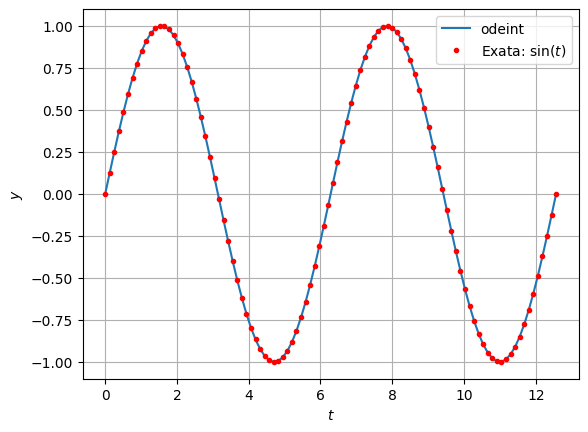

In [3]:
m = 1; c = 0; k = 1;
F = lambda t: 0
t = np.linspace(0,4*np.pi,100)
u0 = [0,1]
y = mass_spring_damper(m,c,k,F,u0,t)
plt.plot(t,y,t,np.sin(t),'r.'), plt.grid(True)
plt.xlabel('$t$'), plt.ylabel('$y$'), plt.legend(['odeint',r'Exata: $\sin(t)$'])
plt.show()

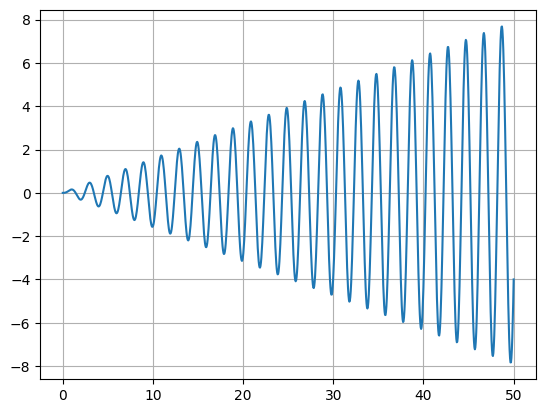

In [4]:
m = 1; c = 0; k = 10;
F = lambda t: np.sin((k/m)**0.5*t)    # frequência igual à natural
t = np.linspace(0,50,1000)
u0 = [0,0]
y = mass_spring_damper(m,c,k,F,u0,t)
plt.plot(t,y), plt.grid(True)
plt.show()

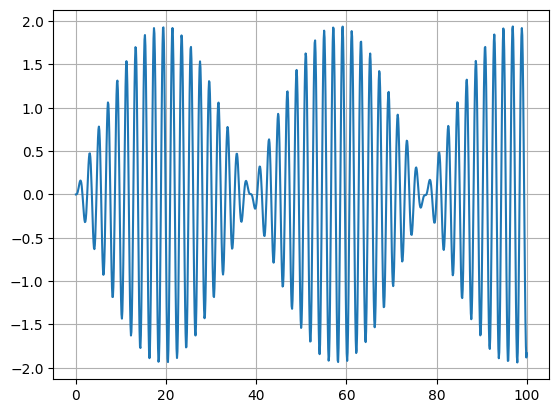

In [5]:
m = 1; c = 0; k = 10;
F = lambda t: np.sin(3*t)
t = np.linspace(0,100,1000)
u0 = [0,0]
y = mass_spring_damper(m,c,k,F,u0,t)
plt.plot(t,y), plt.grid(True)
plt.show()

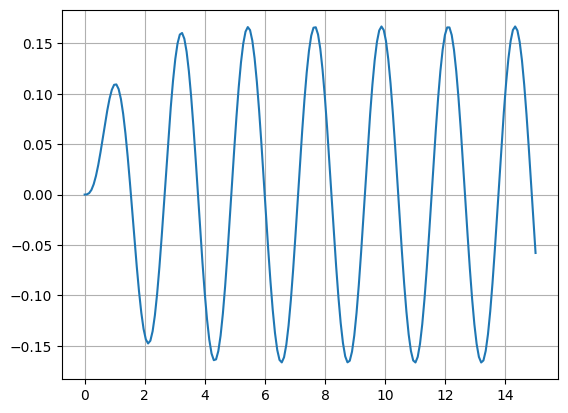

In [6]:
m = 1; c = 2; k = 10;
wr = np.sqrt(k/m - c**2/(2*m**2))    # ressonância prática
F = lambda t: np.sin(wr*t)
t = np.linspace(0,15,200)
u0 = [0,0]
y = mass_spring_damper(m,c,k,F,u0,t)
plt.plot(t,y), plt.grid(True)
plt.show()

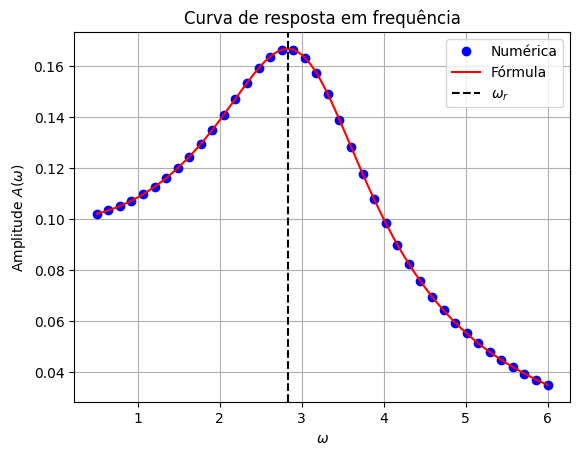

In [7]:
m = 1; c = 2; k = 10;
omegas = np.linspace(0.5,6,40)
A_num = np.zeros(len(omegas))
t = np.linspace(0,40,4000)
for i, w in enumerate(omegas):
    y = mass_spring_damper(m,c,k,lambda t: np.sin(w*t),[0,0],t)
    A_num[i] = np.max(np.abs(y[t > 30]))       # amplitude após o transiente

w_fino = np.linspace(0.5,6,300)
A_exata = 1/np.sqrt((k - m*w_fino**2)**2 + (c*w_fino)**2)
plt.plot(omegas,A_num,'bo',w_fino,A_exata,'r')
plt.axvline(np.sqrt(k/m - c**2/(2*m**2)),color='k',ls='--')
plt.xlabel(r"$\omega$"), plt.ylabel(r"Amplitude $A(\omega)$"), plt.grid(True)
plt.legend(["Numérica","Fórmula",r"$\omega_r$"])
plt.title("Curva de resposta em frequência")
plt.show()

In [8]:
def van_der_pol(mu,u0,t):

    def f(u,t):
        dudt = np.zeros(2)
        dudt[0] = u[1]
        dudt[1] = mu*(1 - u[0]**2)*u[1] - u[0]
        return dudt

    U = spi.odeint(f,u0,t)
    x = U[:,0]
    dxdt = U[:,1]
    return np.column_stack((x,dxdt))

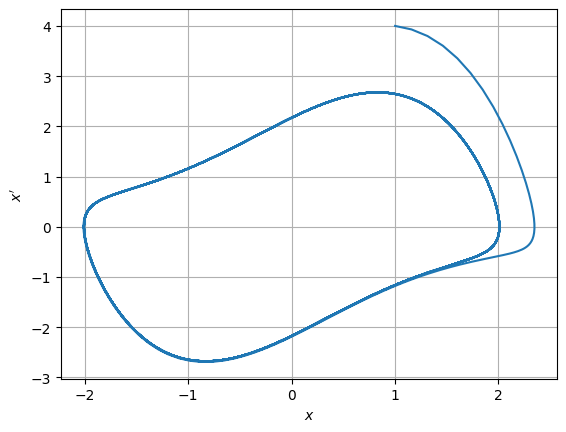

In [9]:
U = van_der_pol(1,[1,4],np.linspace(0,100,2500))
plt.plot(U[:,0],U[:,1]), plt.grid(True)
plt.xlabel("$x$"), plt.ylabel("$x'$")
plt.show()

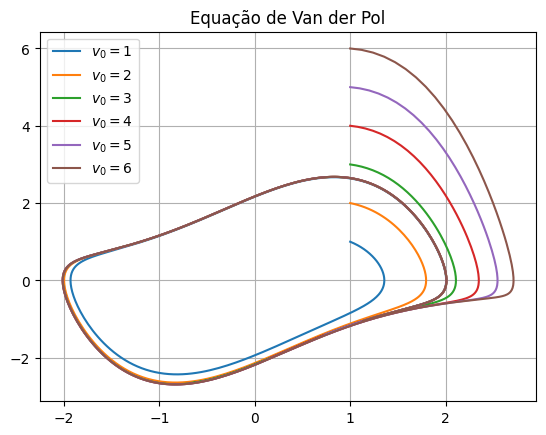

In [10]:
for v0 in [1,2,3,4,5,6]:
    U = van_der_pol(1,[1,v0],np.linspace(0,10,500))
    plt.plot(U[:,0],U[:,1])
plt.title("Equação de Van der Pol")
plt.grid(True), plt.legend(['$v_0=1$','$v_0=2$','$v_0=3$','$v_0=4$','$v_0=5$','$v_0=6$'])
plt.show()

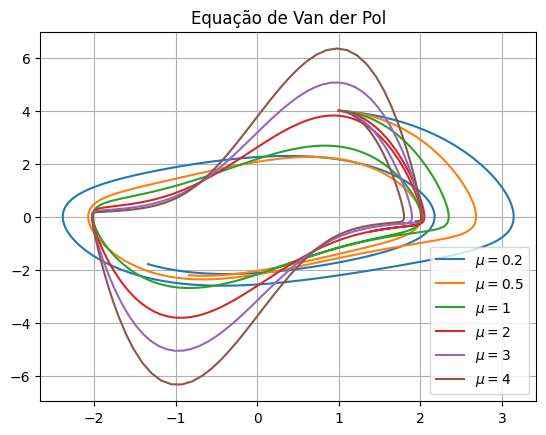

In [11]:
for mu in [0.2,0.5,1,2,3,4]:
    U = van_der_pol(mu,[1,4],np.linspace(0,10,500))
    plt.plot(U[:,0],U[:,1])
plt.title("Equação de Van der Pol")
plt.grid(True), plt.legend([r'$\mu=0.2$',r'$\mu=0.5$',r'$\mu=1$',r'$\mu=2$',r'$\mu=3$',r'$\mu=4$'])
plt.show()

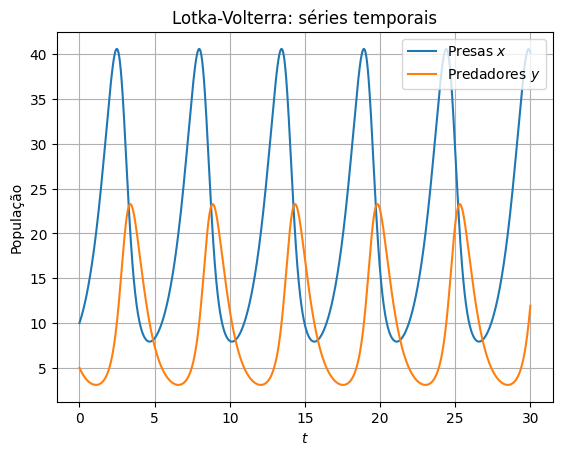

In [12]:
alpha = 1; beta = 0.1; delta = 0.075; gamma = 1.5

def lotka_volterra(u,t):
    x, y = u
    return [alpha*x - beta*x*y, delta*x*y - gamma*y]

t = np.linspace(0,30,2000)
U = spi.odeint(lotka_volterra,[10,5],t)
plt.plot(t,U[:,0],t,U[:,1]), plt.grid(True)
plt.xlabel("$t$"), plt.ylabel("População"), plt.legend(["Presas $x$","Predadores $y$"])
plt.title("Lotka-Volterra: séries temporais")
plt.show()

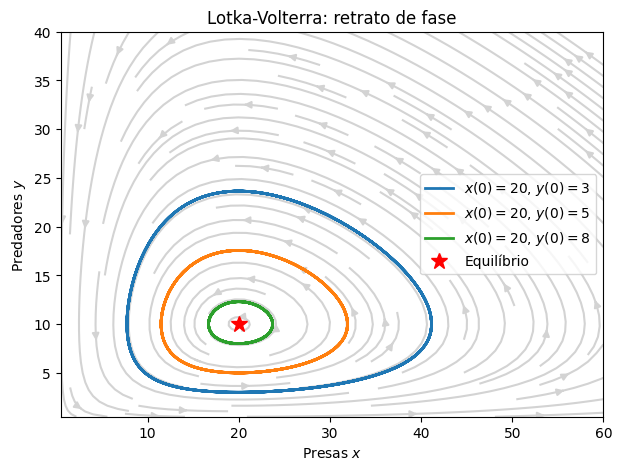

In [13]:
X, Y = np.meshgrid(np.linspace(0.5,60,30),np.linspace(0.5,40,30))
plt.figure(figsize=(7,5))
plt.streamplot(X,Y,alpha*X - beta*X*Y,delta*X*Y - gamma*Y,color='lightgray',density=1.2)
for y0 in [3,5,8]:
    U = spi.odeint(lotka_volterra,[20,y0],t)
    plt.plot(U[:,0],U[:,1],lw=2,label=f"$x(0)=20$, $y(0)={y0}$")
plt.plot(gamma/delta,alpha/beta,'r*',markersize=12,label="Equilíbrio")
plt.xlabel("Presas $x$"), plt.ylabel("Predadores $y$"), plt.legend()
plt.title("Lotka-Volterra: retrato de fase")
plt.show()

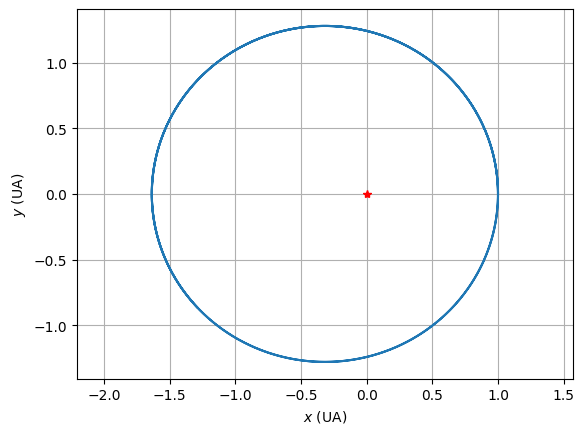

In [14]:
G = 4*np.pi**2; mS = 1;

def f(u,t):
    dudt = np.zeros(4)
    dudt[0] = u[1]
    dudt[1] = -G*mS*u[0]/(u[0]**2 + u[2]**2)**(3/2)
    dudt[2] = u[3]
    dudt[3] = -G*mS*u[2]/(u[0]**2 + u[2]**2)**(3/2)
    return dudt

u0 = [1,0,0,7]
t = np.linspace(0,4,2000)
U = spi.odeint(f,u0,t)
plt.plot(U[:,0],U[:,2],0,0,'r*')
plt.xlabel('$x$ (UA)'), plt.ylabel('$y$ (UA)')
plt.axis('equal'), plt.grid(True)
plt.show()

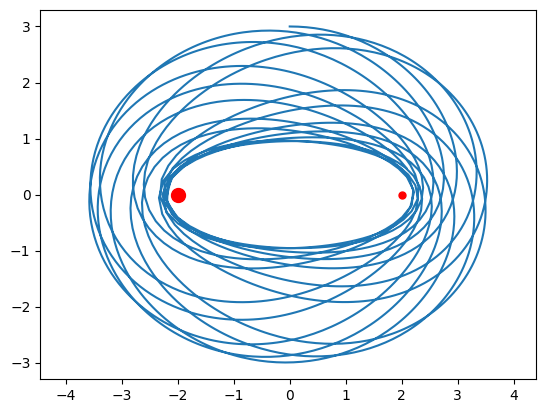

In [15]:
G = 4*np.pi**2   # constante gravitacional (UA, anos, massas solares)
S1 = [-2,0]      # coordenadas da estrela 1
S2 = [2,0]       # coordenadas da estrela 2
M1 = 2           # massa da estrela 1 (em massas solares)
M2 = 1           # massa da estrela 2 (em massas solares)

def f(u,t):
    d1 = np.linalg.norm([u[0] - S1[0],u[2] - S1[1]])
    d2 = np.linalg.norm([u[0] - S2[0],u[2] - S2[1]])
    dudt = np.zeros(4)
    dudt[0] = u[1]
    dudt[1] = -G*M1*(u[0] - S1[0])/d1**3 - G*M2*(u[0] - S2[0])/d2**3
    dudt[2] = u[3]
    dudt[3] = -G*M1*(u[2] - S1[1])/d1**3 - G*M2*(u[2] - S2[1])/d2**3
    return dudt

u0 = [0,5,3,0]                # condições iniciais do planeta: [x, x', y, y']
t = np.linspace(0,30,2000)    # tempo (em anos)
u = spi.odeint(f,u0,t)        # u = [x, x', y, y']

plt.plot(u[:,0],u[:,2])                          # trajetória do planeta
plt.plot(S1[0],S1[1],'ro',markersize=5*M1)       # estrela 1 (círculo vermelho)
plt.plot(S2[0],S2[1],'ro',markersize=5*M2)       # estrela 2 (círculo vermelho)
plt.axis('equal')
plt.show()

In [16]:
def euler3body(S1,S2,M1,M2,u0,tf,numpoints=1000):

    # lado direito do sistema de equações
    def f(u,t):
        d1 = np.linalg.norm([u[0]-S1[0],u[2]-S1[1]])
        d2 = np.linalg.norm([u[0]-S2[0],u[2]-S2[1]])
        dudt = np.zeros(4)
        dudt[0] = u[1]
        dudt[1] = -G*M1*(u[0]-S1[0])/d1**3 - G*M2*(u[0]-S2[0])/d2**3
        dudt[2] = u[3]
        dudt[3] = -G*M1*(u[2]-S1[1])/d1**3 - G*M2*(u[2]-S2[1])/d2**3
        return dudt

    t = np.linspace(0,tf,numpoints)   # tempo (em anos)
    u = spi.odeint(f,u0,t)            # u = [x, x', y, y']

    plt.plot(u[:,0],u[:,2])                          # trajetória do planeta
    plt.plot(S1[0],S1[1],'ro',markersize=5*M1)       # estrela 1
    plt.plot(S2[0],S2[1],'ro',markersize=5*M2)       # estrela 2
    plt.axis('equal')
    plt.show()

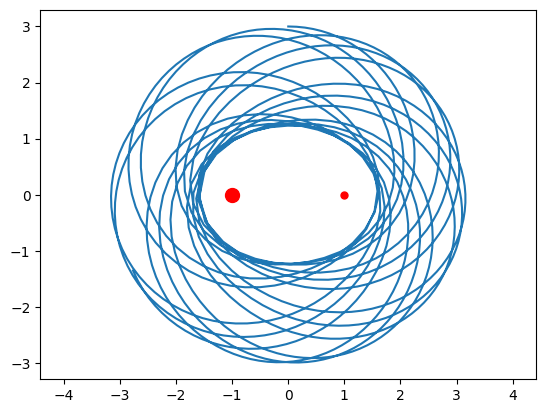

In [17]:
euler3body([-1,0],[1,0],2,1,[0,5,3,0],30)

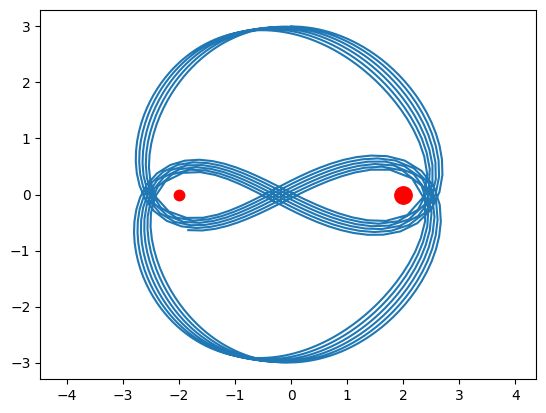

In [18]:
euler3body([-2,0],[2,0],1.5,2.5,[0,4.8,3,0],20)

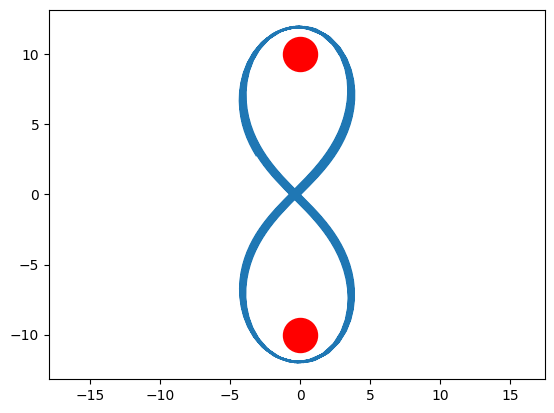

In [19]:
euler3body([0,10],[0,-10],4.9,4.9,[0,np.pi,0,np.pi],100)